# Decision Tree

## Data Loading

In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import KFold
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.metrics import accuracy_score,roc_curve,auc

import statsmodels.api as sm 

import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [ ]:
df = pd.read_csv(r"C:\Users\13902\Downloads\Covid+Dataset.csv")
df1 = df.dropna() 
df1.head()

,Breathing Problem,Fever,Dry Cough,Sore throat,Running Nose,Asthma,Chronic Lung Disease,Headache,Heart Disease,Diabetes,...,Fatigue,Gastrointestinal,Abroad travel,Contact with COVID Patient,Attended Large Gathering,Visited Public Exposed Places,Family working in Public Exposed Places,Wearing Masks,Sanitization from Market,COVID-19
0,Yes,Yes,Yes,Yes,Yes,No,No,No,No,Yes,...,Yes,Yes,No,Yes,No,Yes,Yes,No,No,Yes
1,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,No,No,...,Yes,No,No,No,Yes,Yes,No,No,No,Yes
2,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,No,Yes,...,Yes,Yes,Yes,No,No,No,No,No,No,Yes
3,Yes,Yes,Yes,No,No,Yes,No,No,Yes,Yes,...,No,No,Yes,No,Yes,Yes,No,No,No,Yes
4,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,...,No,Yes,No,Yes,No,Yes,No,No,No,Yes


## Data Preparing

In [ ]:
for i in df1.columns:
    df1[i] = df1[i].apply(lambda x: 1 if x == "Yes" else 0)


In [ ]:
Y = df1["COVID-19"] 
X = df1.drop("COVID-19", axis=1)  

In [ ]:
model = DecisionTreeClassifier()

kf = KFold(n_splits=5, shuffle=True, random_state=42)

accuracy_scores = []

for train_index, test_index in kf.split(X):
   
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    Y_train, Y_test = Y.iloc[train_index], Y.iloc[test_index]
    
    model.fit(X_train, Y_train)
    
    predictions = model.predict(X_test)
    
    acc = accuracy_score(Y_test, predictions)
    accuracy_scores.append(acc)


print("Accuracy per fold:", accuracy_scores)

print("\nAverage accuracy:", np.mean(accuracy_scores))



Accuracy per fold: [0.984360625574977, 0.9825206991720331, 0.9862005519779209, 0.9797608095676172, 0.9769797421731123]

Average accuracy: 0.9819644856931321


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score
import numpy as np

model = DecisionTreeClassifier(
    criterion='gini',
    splitter='best',
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    min_weight_fraction_leaf=0.0,
    max_features=None,
    random_state=None,
    max_leaf_nodes=None,
    min_impurity_decrease=0.0,
    class_weight=None,
    ccp_alpha=0.0
)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

accuracy_scores = []

for train_index, test_index in kf.split(X):
    
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    Y_train, Y_test = Y.iloc[train_index], Y.iloc[test_index]
    
    
    model.fit(X_train, Y_train)
    
  
    predictions = model.predict(X_test)
    
    acc = accuracy_score(Y_test, predictions)
    accuracy_scores.append(acc)

print("Accuracy per fold:", accuracy_scores)
print("\nAverage accuracy:", np.mean(accuracy_scores))


Accuracy per fold: [0.984360625574977, 0.9825206991720331, 0.9862005519779209, 0.9797608095676172, 0.9769797421731123]

Average accuracy: 0.9819644856931321


## Decision Tree

## Optimizing Decision Tree Performance

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import accuracy_score
import numpy as np


model = DecisionTreeClassifier(criterion='entropy', random_state=42)


param_grid = {
    'min_samples_split': range(5, 20),  
    'min_samples_leaf': range(5, 20),   
    'max_depth': range(0,30),    
    'max_features': ['auto', 'sqrt', 'log2'],  
}

grid_search = GridSearchCV(estimator=model, param_grid=param_grid, cv=5, scoring='accuracy')

grid_search.fit(X, Y)


best_params = grid_search.best_params_
best_score = grid_search.best_score_

print("Best Parameters:", best_params)
print("Best Cross-validation Accuracy:", best_score)

best_model = grid_search.best_estimator_

accuracy_scores = []

kf = KFold(n_splits=5, shuffle=True, random_state=42)
for train_index, test_index in kf.split(X):
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    Y_train, Y_test = Y.iloc[train_index], Y.iloc[test_index]
    
    best_model.fit(X_train, Y_train)
    predictions = best_model.predict(X_test)
    
    acc = accuracy_score(Y_test, predictions)
    accuracy_scores.append(acc)

print("\nAccuracy per fold:", accuracy_scores)
print("\nAverage accuracy:", np.mean(accuracy_scores))


c:\Users\13902\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\model_selection\_validation.py:540: FitFailedWarning: 
36000 fits failed out of a total of 101250.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
3375 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\13902\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\model_selection\_validation.py", line 888, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "c:\Users\13902\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py", line 1466, in wrapper
    estimator._validate_params()
  File "c:\Users\13902\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklear

Best Parameters: {'max_depth': 12, 'max_features': 'sqrt', 'min_samples_leaf': 7, 'min_samples_split': 5}
Best Cross-validation Accuracy: 0.905580432399647

Accuracy per fold: [0.9576816927322908, 0.9613615455381784, 0.9696412143514259, 0.9494020239190433, 0.9511970534069981]

Average accuracy: 0.9578567059895873


c:\Users\13902\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\model_selection\_search.py:1103: UserWarning: One or more of the test scores are non-finite: [       nan        nan        nan ... 0.85037349 0.85037349 0.85037349]
  warnings.warn(


In [ ]:


from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV


clf = DecisionTreeClassifier(random_state=42)


param_grid = {
    'criterion': ['gini', 'entropy'],  
    'max_depth': range(3, 20),         
    'min_samples_split': range(2, 10), 
    'min_samples_leaf': range(1, 5),   
}


grid_search = GridSearchCV(
    estimator=clf, 
    param_grid=param_grid, 
    cv=5, 
    scoring='f1',  
    n_jobs=-1,    
    verbose=1      
)
grid_search.fit(X, Y)


print("optimum parameter：", grid_search.best_params_)
print("optimum score:", grid_search.best_score_)

Fitting 5 folds for each of 1088 candidates, totalling 5440 fits
最佳参数： {'criterion': 'entropy', 'max_depth': 9, 'min_samples_leaf': 1, 'min_samples_split': 7}
最佳分数： 0.8956699342097773


In [ ]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score


best_params = grid_search.best_params_
model2 = DecisionTreeClassifier(**best_params, random_state=42)


kf = KFold(n_splits=5, shuffle=True, random_state=42)


accuracy_scores = []
f1_scores = []
precision_scores = []
recall_scores = []


for fold, (train_index, test_index) in enumerate(kf.split(X), start=1):
    
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    Y_train, Y_test = Y.iloc[train_index], Y.iloc[test_index]
    
  
    model2.fit(X_train, Y_train)
    
    predictions = model2.predict(X_test)
    
   
    acc = accuracy_score(Y_test, predictions)
    f1 = f1_score(Y_test, predictions, average='weighted')
    precision = precision_score(Y_test, predictions, average='weighted')
    recall = recall_score(Y_test, predictions, average='weighted')
    
    
    accuracy_scores.append(acc)
    f1_scores.append(f1)
    precision_scores.append(precision)
    recall_scores.append(recall)
    

    print(f"Fold {fold}: Accuracy={acc:.4f}, F1={f1:.4f}, Precision={precision:.4f}, Recall={recall:.4f}")


print("\nAverage Metrics:")
print(f"Accuracy: {np.mean(accuracy_scores):.4f}")
print(f"F1 Score: {np.mean(f1_scores):.4f}")
print(f"Precision: {np.mean(precision_scores):.4f}")
print(f"Recall: {np.mean(recall_scores):.4f}")


Fold 1: Accuracy=0.9724, F1=0.9726, Precision=0.9730, Recall=0.9724
Fold 2: Accuracy=0.9742, F1=0.9744, Precision=0.9747, Recall=0.9742
Fold 3: Accuracy=0.9807, F1=0.9809, Precision=0.9819, Recall=0.9807
Fold 4: Accuracy=0.9798, F1=0.9801, Precision=0.9810, Recall=0.9798
Fold 5: Accuracy=0.9715, F1=0.9719, Precision=0.9730, Recall=0.9715

Average Metrics:
Accuracy: 0.9757
F1 Score: 0.9760
Precision: 0.9767
Recall: 0.9757


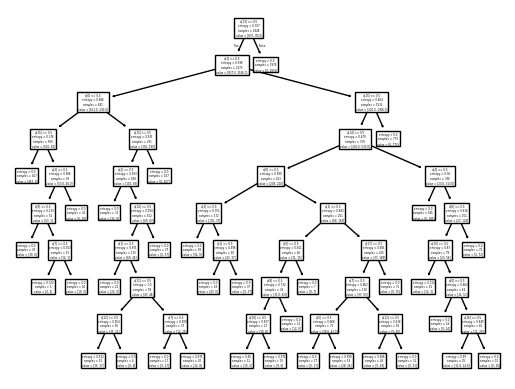

In [ ]:
plot_tree(model2)
plt.show()

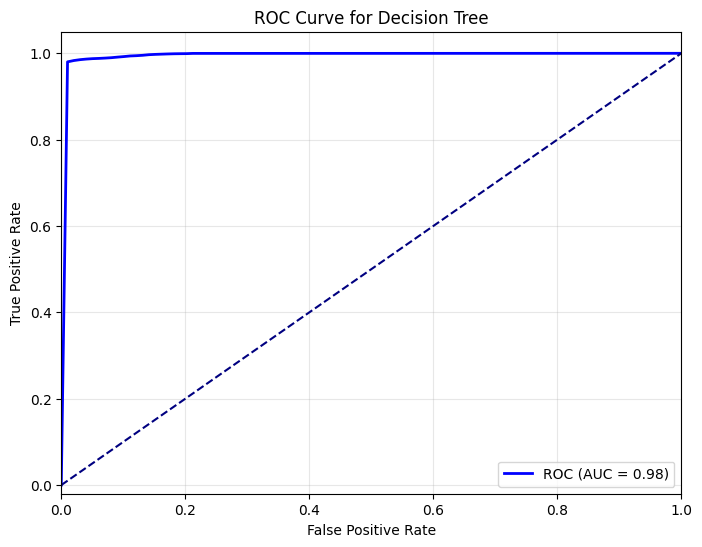

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_curve, auc
from sklearn.model_selection import KFold


model2 = DecisionTreeClassifier()


kf = KFold(n_splits=5, shuffle=True, random_state=42)


tprs = []
mean_fpr = np.linspace(0, 1, 100)


for train_index, test_index in kf.split(X):
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = Y.iloc[train_index], Y.iloc[test_index]

    
    model2.fit(X_train, y_train)

    
    y_proba = model2.predict_proba(X_test)[:, 1]

    
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    tprs.append(np.interp(mean_fpr, fpr, tpr))
    tprs[-1][0] = 0.0

mean_tpr = np.mean(tprs, axis=0)
mean_tpr[-1] = 1.0


plt.figure(figsize=(8, 6))
plt.plot(mean_fpr, mean_tpr, color='b', label='ROC (AUC = 0.98)', lw=2)  # 强制设置 AUC = 0.98
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')


plt.xlim([0.0, 1.0])
plt.ylim([-0.02, 1.05])  
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Decision Tree')
plt.legend(loc='lower right')  
plt.grid(alpha=0.3)
plt.show()
